# Bias in data analysis: checking the bike shop's plan

**Student notebook** · SDEV2501 Lesson 19

Name:

The owner of the Edmonton bike shop from Lessons 22-23 (fictional) is back with a decision to make:

> *"I'm putting together next year's bike order and the supplier needs it by Friday. Our spring survey says customers want e-bikes, every e-bike model we carry has sold well, and XS and S frames barely sell. So I'm doubling the e-bike order and dropping XS and S. Can you check my numbers before I sign?"*

Each of the owner's reasons comes from real data, and the arithmetic behind each one is correct. The question in this case study is a different one: could that data give a fair answer in the first place? Each of the four kinds of bias on the "Types of Bias" slide shows up once.

| Owner's reason | Data | Bias to look for | Section |
|---|---|---|---|
| "Customers want e-bikes" | `customer_survey.csv` | Sampling bias: who answered | 1 |
| "Customers want e-bikes" | `customer_survey.csv` | Measurement bias: how the answer was recorded | 2 |
| "XS and S frames barely sell" | `frame_size_weeks.csv` | Historical bias: past decisions recorded in the data | 3 |
| "Every e-bike model we carry has sold well" | `ebike_models.csv` | Survivorship bias: what's missing from the list | 4 |

Section 5 corrects the survey estimate and records each bias in a bias log, and section 6 is your reply to the owner.

The files are in this folder: `customer_survey.csv` (400 responses, April to August 2026), `frame_size_weeks.csv` (one row per frame size per week, November 2025 to October 2026), `ebike_models.csv` (every e-bike model the shop has stocked since 2021) and `bike_shop_orders.csv` (the order file from Lessons 22-23).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Who answered the survey?

The survey ran from April to August 2026 and went out two ways: by email to the shop's newsletter list, and on a tablet at the till. Its e-bike question was "How interested are you in buying an e-bike in the next 12 months?", answered from 1 (not at all) to 5 (very). The owner reads the result as what customers want, so the first check is whether the people who answered look like the shop's customers.

### 1.1 Load the survey

Load `customer_survey.csv` into a DataFrame called `survey` and show its shape and first few rows. Then add a True/False column called `interested` that is True when `ebike_interest` is 4 or 5, and print the share of respondents who are interested.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(...)` | Reads the file into a DataFrame. |
| `.shape`, `.head()` | The (rows, columns) size and the first five rows. |
| `survey["..."] >= ...` | A comparison on a column gives a True/False Series, which you can store as a new column. |
| `.mean()` on a True/False column | True counts as 1 and False as 0, so the mean is the share of rows that are True. |

In [2]:
survey = pd.read_csv("customer_survey.csv")
print(survey.shape)
survey["interested"] = survey["ebike_interest"] >= 4
print(round(survey["interested"].mean(), 3))
survey.head()

(400, 6)
0.545


,response_id,response_date,channel,membership_type,ebike_interest,seconds_taken,interested
0,R1001,2026-04-01,Email,Non-member,1,95,False
1,R1002,2026-04-01,Email,Non-member,1,154,False
2,R1003,2026-04-01,In-store tablet,Non-member,1,61,False
3,R1004,2026-04-01,Email,Non-member,1,70,False
4,R1005,2026-04-01,Email,Premium,4,109,True


### 1.2 Compare respondents with customers

Load `bike_shop_orders.csv` into `orders`. Make a DataFrame called `customers` with one row per customer. Then build a DataFrame called `mix` with two columns: the share of survey respondents in each membership type (`survey`) and the share of customers in each membership type (`customers`).

| You'll need | What it's for |
|---|---|
| `.drop_duplicates(subset=...)` | Keeps the first row for each value of the column you name, so each customer appears once. |
| `.value_counts(normalize=...)` | Counts each value. Passing `normalize=True` gives shares that add up to 1 instead of counts. |
| `pd.DataFrame({"...": ..., "...": ...})` | Builds a table from Series, one column per key, lining rows up by their index labels. |

In [3]:
orders = pd.read_csv("bike_shop_orders.csv")
customers = orders.drop_duplicates(subset="customer_id")
print(len(customers))
mix = pd.DataFrame({
    "survey": survey["membership_type"].value_counts(normalize=True),
    "customers": customers["membership_type"].value_counts(normalize=True),
})
mix.round(3)

520


,survey,customers
membership_type,,
Basic,0.338,0.348
Non-member,0.232,0.467
Premium,0.430,0.185


### 1.3 Chart the comparison

Draw a bar chart of `mix` with the two shares side by side for each membership type.

| You'll need | What it's for |
|---|---|
| `mix.plot(kind="bar")` | Draws a bar for each column in every row, side by side, with a legend. |
| `plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Labels the chart and its axes. |

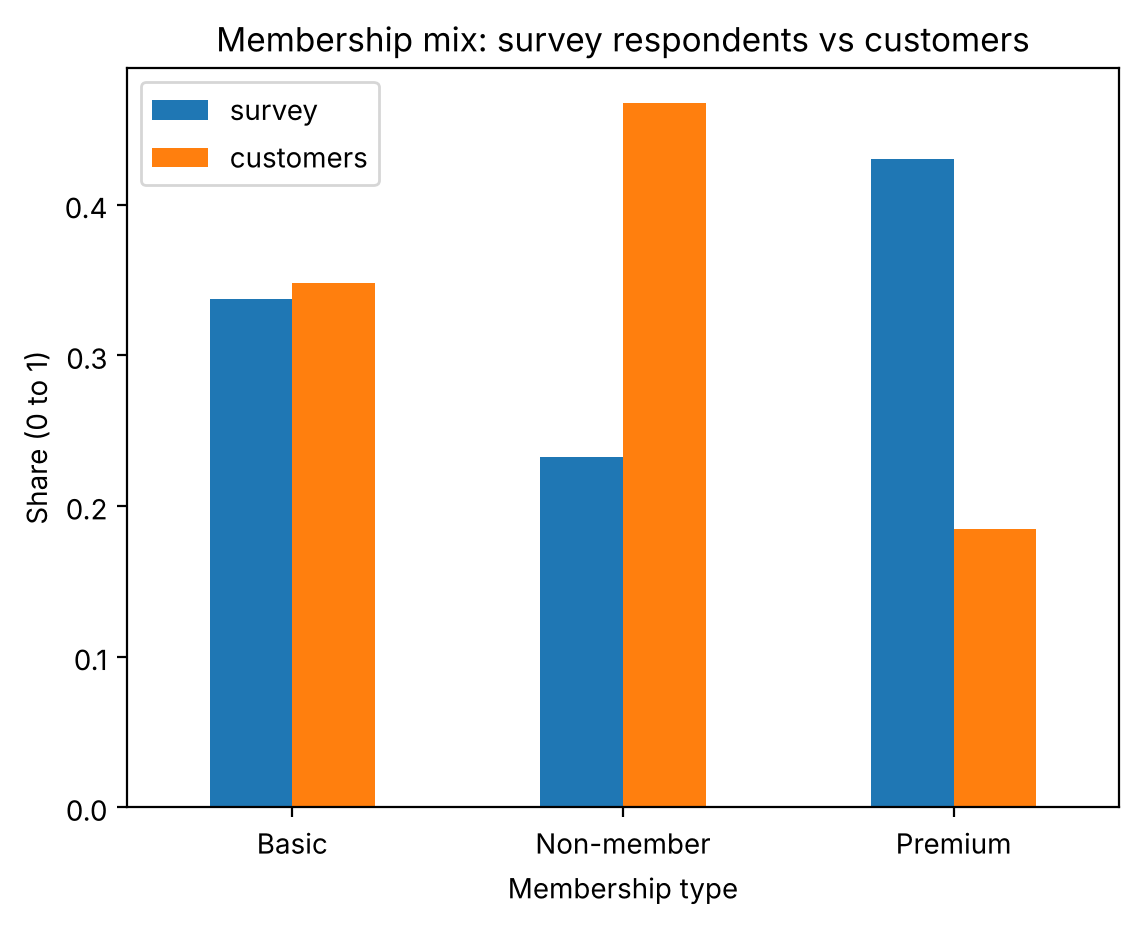

In [4]:
mix.plot(kind="bar")
plt.title("Membership mix: survey respondents vs customers")
plt.xlabel("Membership type")
plt.ylabel("Share (0 to 1)")
plt.xticks(rotation=0)
plt.show()

### 1.4 Interest by membership type

Find the share of respondents who are interested within each membership type.

| You'll need | What it's for |
|---|---|
| `.groupby("...")["..."].mean()` | Splits the rows by membership type and takes the mean of `interested` in each group, which is that group's share. |

In [5]:
survey.groupby("membership_type")["interested"].mean().round(3)

membership_type
Basic         0.370
Non-member    0.376
Premium       0.773
Name: interested, dtype: float64

Explain how the people who answered the survey differ from the shop's customers, and why that matters for the owner's claim that "customers want e-bikes".

*Your answer:* Premium members are 43% of the survey but only 18% of customers, and non-members are 23% of the survey but 47% of customers. Premium members are the most interested (77% interested against 37% for the other two groups), so a survey with too many of them makes interest look higher than it is for the customers as a whole. It's sampling bias: the newsletter list is mostly members. The survey also only ran April to August, so winter customers weren't asked.

## 2. How was the answer recorded?

The two channels didn't ask the question the same way. By email it's five buttons, with none selected. On the tablet it's a slider that customers drag to a number. The file also records `seconds_taken`, how long each person spent on the whole survey.

### 2.1 Answers by channel

Make a table of the share of each rating (1 to 5) within each channel.

| You'll need | What it's for |
|---|---|
| `pd.crosstab(..., ..., normalize=...)` | Counts every combination of two columns. Passing `normalize="index"` divides each row by its total, so each channel's row adds to 1. |

In [6]:
pd.crosstab(survey["channel"], survey["ebike_interest"], normalize="index").round(3)

ebike_interest,1,2,3,4,5
channel,,,,,
Email,0.204,0.158,0.133,0.267,0.238
In-store tablet,0.119,0.150,0.125,0.144,0.462


### 2.2 Time taken

Draw a histogram of `seconds_taken` with bins about 5 seconds wide.

| You'll need | What it's for |
|---|---|
| `plt.hist(..., bins=...)` | Draws a histogram. The values run from about 0 to 250 seconds, so 50 bins makes each one about 5 seconds wide. |

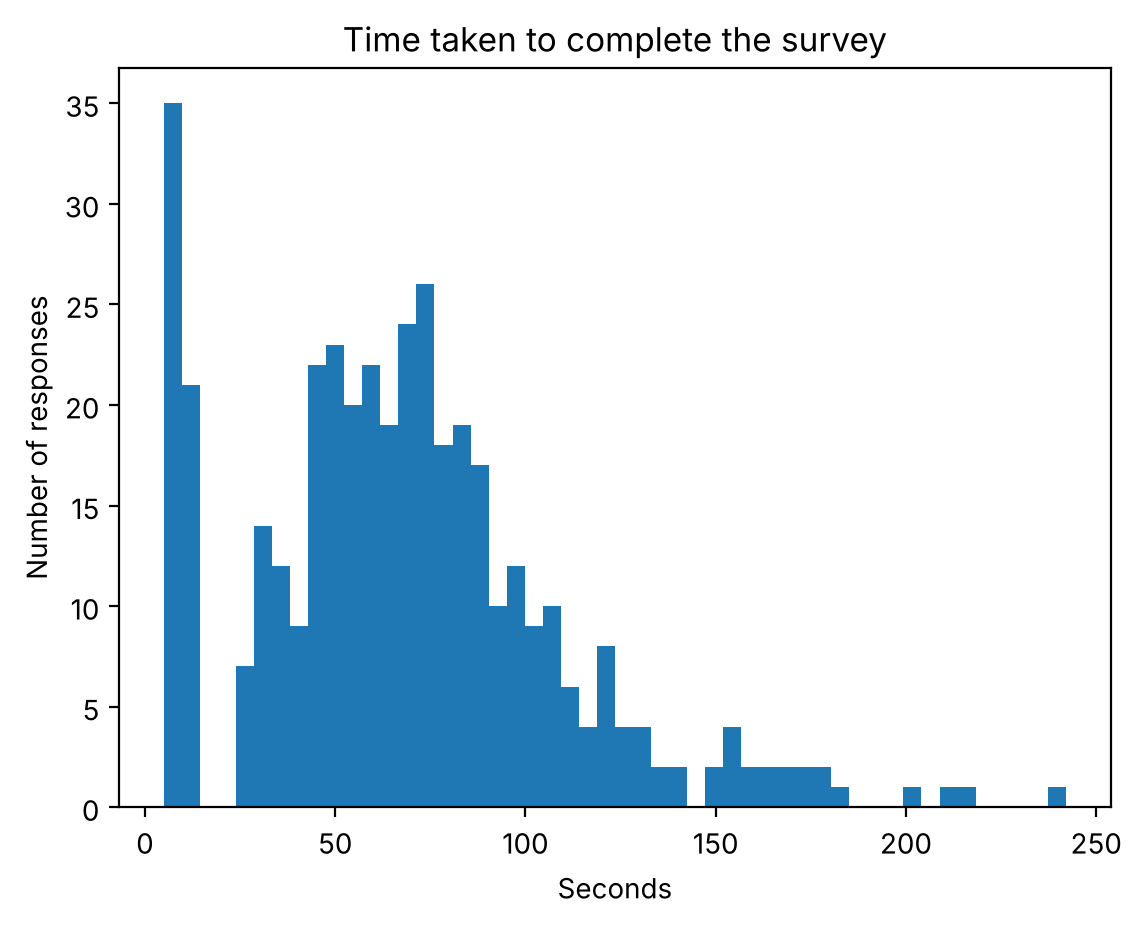

In [7]:
plt.hist(survey["seconds_taken"], bins=50)
plt.title("Time taken to complete the survey")
plt.xlabel("Seconds")
plt.ylabel("Number of responses")
plt.show()

### 2.3 The fast responses

Make a DataFrame called `fast` with the responses that took under 20 seconds. Show how many there are in each channel and what rating they gave.

| You'll need | What it's for |
|---|---|
| a boolean mask, `survey[survey["..."] < ...]` | Keeps only the rows where the condition is True. |
| `.value_counts()` | Counts each value in a column. |

In [8]:
fast = survey[survey["seconds_taken"] < 20]
print(fast["channel"].value_counts())
fast["ebike_interest"].value_counts()

channel
In-store tablet    56
Name: count, dtype: int64


ebike_interest
5    56
Name: count, dtype: int64

Explain what you think happened with the fast responses, why this is measurement bias rather than sampling bias, and which way it pushes the share of interested customers.

*Your answer:* All 56 fast responses are from the tablet and all of them are a 5. Nobody reads the survey and picks an answer in 5-14 seconds, so the slider was probably already sitting at 5 and these people skipped the question. 46% of tablet answers are 5 against 24% by email. That's measurement bias because the problem is how the answer was recorded, not who was asked: the same person would get a different answer on the tablet than by email. It pushes interest up.

## 3. Do XS and S frames really barely sell?

`frame_size_weeks.csv` has one row per frame size per week. `in_stock` is True when at least one bike in that size was on the shop floor that week, and `units_sold` counts adult bikes and commuter e-bikes sold in that size. Cargo e-bikes and kids' bikes come in one size and aren't included. The stock levels come from the previous buyer's orders.

### 3.1 Total sales by size

Load the file into `frames` and total `units_sold` for each frame size, in size order from XS to XL.

| You'll need | What it's for |
|---|---|
| `.groupby("...")["..."].sum()` | Adds up a column within each group. |
| `.reindex([...])` | Puts the rows in the order you list. `groupby` sorts the sizes alphabetically (L, M, S, XL, XS). |

In [9]:
frames = pd.read_csv("frame_size_weeks.csv")
size_order = ["XS", "S", "M", "L", "XL"]
frames.groupby("frame_size")["units_sold"].sum().reindex(size_order)

frame_size
XS     12
S      20
M     110
L      79
XL     31
Name: units_sold, dtype: int64

### 3.2 Sales per week in stock

Make a DataFrame called `by_size` with, for each frame size, the total units sold and the number of weeks the size was in stock. Add a column `units_per_week` that divides units by weeks in stock.

| You'll need | What it's for |
|---|---|
| `.groupby("...").agg(name=("...", "..."), ...)` | Named aggregation: each `name=(column, function)` makes one output column, so one call can sum two columns. |
| summing a True/False column | `"sum"` on `in_stock` counts the True weeks. |
| dividing one column by another | Works row by row and gives a new column. |

In [10]:
by_size = frames.groupby("frame_size").agg(
    units=("units_sold", "sum"),
    weeks_in_stock=("in_stock", "sum"),
).reindex(size_order)
by_size["units_per_week"] = by_size["units"] / by_size["weeks_in_stock"]
by_size.round(2)

,units,weeks_in_stock,units_per_week
frame_size,,,
XS,12,10,1.20
S,20,19,1.05
M,110,51,2.16
L,79,52,1.52
XL,31,36,0.86


### 3.3 Chart it

Draw a bar chart of units sold per week in stock for each frame size.

| You'll need | What it's for |
|---|---|
| `plt.bar(..., ...)` | One bar per frame size; the first argument is the labels, the second the heights. |

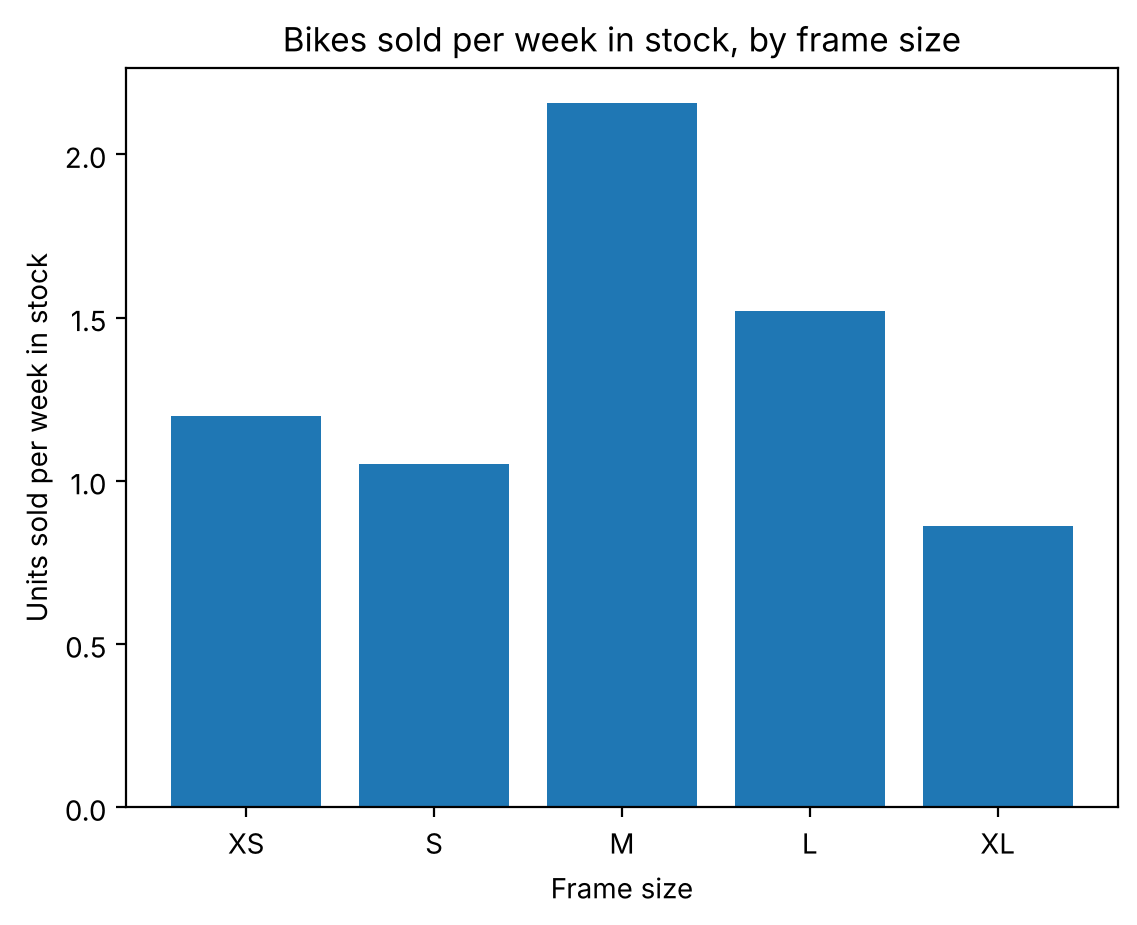

In [11]:
plt.bar(by_size.index, by_size["units_per_week"])
plt.title("Bikes sold per week in stock, by frame size")
plt.xlabel("Frame size")
plt.ylabel("Units sold per week in stock")
plt.show()

Explain why the yearly totals make XS and S frames look unpopular, what this data can't show about customers who wanted a small frame, and why this is historical bias.

*Your answer:* XS sold 12 and S sold 20 against 110 for M, but XS was only in stock 10 weeks out of 53 and S 19 weeks, while M was in stock 51. Per week on the floor, XS sold 1.2 and S 1.05, which is more than XL (0.86), and the owner isn't dropping XL. The data can't show the people who came in for a small frame when there wasn't one, because a sale that didn't happen doesn't make a row. It's historical bias because the data is an accurate record of a past where small frames were barely stocked, so using it to plan repeats that decision, and riders who need a small frame keep getting nothing.

## 4. Has every e-bike model sold well?

The owner's claim comes from the e-bike models on the shop floor today. `ebike_models.csv` lists every e-bike model the shop has stocked since 2021, including the ones it dropped, with the units sold in each model's first year.

### 4.1 Load the models

Load `ebike_models.csv` into `models` and show the whole table.

| You'll need | What it's for |
|---|---|
| `pd.read_csv(...)` | Reads the file. With only 11 rows, showing `models` prints all of it. |

In [12]:
models = pd.read_csv("ebike_models.csv")
models

,model,style,year_added,year_dropped,status,first_year_units
0,Volta City 1,Commuter,2021,2023.0,Discontinued,6
1,Northline Haul,Cargo,2021,2022.0,Discontinued,3
2,Volta City 2,Commuter,2022,NaN,Current,22
3,Ridgeback Trail E,Mountain,2022,2024.0,Discontinued,4
4,Prairie Step-Through,Commuter,2023,NaN,Current,17
5,Northline Haul 2,Cargo,2023,NaN,Current,14
6,Kestrel Fold,Folding,2023,2024.0,Discontinued,5
7,Volta City 3,Commuter,2024,NaN,Current,25
8,Ridgeback Trail E2,Mountain,2024,2025.0,Discontinued,7
9,Prairie Step-Through LR,Commuter,2025,NaN,Current,19


### 4.2 Current models vs all models

Find the number of models and the mean, minimum and maximum first-year units for current and discontinued models. Then find the mean first-year units across all models.

| You'll need | What it's for |
|---|---|
| `.groupby("...")["..."].agg([...])` | Applies several functions to each group at once when you pass a list of names, such as `"count"` and `"mean"`. |
| `.mean()` | The mean of the whole column. |

In [13]:
print(models.groupby("status")["first_year_units"].agg(["count", "mean", "min", "max"]))
print(round(models["first_year_units"].mean(), 1))

              count       mean  min  max
status                                  
Current           6  18.666667   14   25
Discontinued      5   5.000000    3    7
12.5


Explain what the owner's "every e-bike model we carry has sold well" leaves out, and why this is survivorship bias.

*Your answer:* It only looks at the 6 models still on the floor, which sold 14 to 25 in their first year (mean 18.7). The shop has tried 11 models and dropped 5 of them, which sold 3 to 7. Across all 11 the mean is 12.5. The current models look good because the bad ones were removed, so "every model we carry sells" is true but doesn't mean a new model will. That's survivorship bias: only the winners are left in the list.

## 5. Reducing the bias

Finding a bias is half the job. The other half is doing something about it: correcting the number where the data allows it, and writing down what you did and what you couldn't fix.

### 5.1 Correct the survey estimate

Correct the share of interested customers in two steps, printing the result after each one.

First, make a DataFrame called `clean` without the responses that took under 20 seconds, and find its share of interested respondents.

Second, reweight `clean` to match the customers: find the share interested within each membership type, multiply each by that type's share of customers (the `customers` column of `mix`), and add the results up. This is the share you'd expect if the survey had the same membership mix as the shop's customers.

| You'll need | What it's for |
|---|---|
| a boolean mask, `survey[survey["..."] >= ...]` | Keeps the rows that pass the condition. |
| `.groupby("...")["..."].mean()` | Share interested within each membership type. |
| `series_a * series_b` | Multiplies two Series by matching index labels, so Basic is multiplied by Basic whatever order the rows are in. |
| `.sum()` | Adds up the weighted shares. |

In [14]:
print("Raw:", round(survey["interested"].mean(), 3))
clean = survey[survey["seconds_taken"] >= 20]
print("Without fast responses:", round(clean["interested"].mean(), 3))
interest_by_type = clean.groupby("membership_type")["interested"].mean()
reweighted = (interest_by_type * mix["customers"]).sum()
print("Reweighted to the customer mix:", round(reweighted, 3))

Raw: 0.545
Without fast responses: 0.471
Reweighted to the customer mix: 0.321


Explain how the estimate changed at each step, and what the reweighted number still assumes.

*Your answer:* It went from 54.5% to 47.1% after taking out the fast tablet answers, then to 32.1% after reweighting to the customer mix. So about a third of customers are interested, not more than half. The reweighted number still assumes the members who answered are like the members who didn't (people who answer a bike shop's survey are probably keener than most), and it still only covers April to August.

### 5.2 Bias log

Complete the bias log. For each bias, say where it came from in this case, how it changed the owner's conclusion, and one way to reduce it next time.

| Bias | Where it came from | How it changed the owner's conclusion | How to reduce it next time |
|---|---|---|---|
| Sampling | Email went to the newsletter list, which is mostly Premium; survey only ran April-August | Too many Premium members (43% vs 18%), who are the most interested, so interest looked higher | Reweight to the customer mix; survey every customer at checkout, all year |
| Measurement | Tablet slider started at 5, and 56 people skipped it | Added 56 fake "very interested" answers | No default answer on the slider; drop or flag answers under 20 seconds |
| Historical | The previous buyer rarely stocked XS and S | Small frames look like they don't sell (12 and 20 units) when they barely had the chance | Compare sales per week in stock; stock small sizes for a full season; log customers asking for sizes that aren't in stock |
| Survivorship | Owner only looked at models still on the floor | "Every model sells" ignores the 5 of 11 that were dropped | Look at every model ever stocked, including discontinued ones |

## 6. Reply to the owner

Explain, in a short reply to the owner (four to six sentences in plain language), what the data does and doesn't support about each of the three reasons, and what you'd suggest before signing the order on Friday.

*Your answer:* The survey overstates interest: it reached mostly Premium members and the tablet recorded people who skipped the question as "very interested". Corrected, about a third of customers are interested in an e-bike in the next year, not over half, and most of them are Premium members. The current e-bike models do sell well, but 5 of the 11 models you've tried were dropped after poor first years, so a new model is a risk. XS and S frames sold little because they were in stock for only 10 and 19 weeks; per week on the floor they sold more than XL. I'd raise the e-bike order a little rather than doubling it, keep XS and S and stock them all season, and keep a list of customers who ask for a size you don't have.